# Polars Lazy API & Performance

In **lazy** mode, Polars does not run each step immediately. It records the steps as a **query plan**, optimises the plan (reads only the needed columns, pushes filters down to the file reader, removes unused work), and runs it on `collect()`. With the **streaming** engine, it processes data in batches and can handle datasets larger than memory.

**After this lesson you can:**

1. Build lazy queries with `scan_parquet` and run them with `collect()`.
2. Read query plans and recognise projection and predicate pushdown.
3. Use the streaming engine and write results with `sink_parquet`.
4. Compare eager, lazy and streaming execution in time and memory.

**Data:** NYC yellow taxi trips, January and February 2024 (about 6 million rows in two Parquet files).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

import polars as pl

JAN, FEB = datasets.taxi("2024-01"), datasets.taxi("2024-02")
zones_pl = pl.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

def show_plan(text: str) -> None:
    """Print a query plan without the local folder of the data files."""
    print(text.replace(str(JAN.parent) + "/", "").replace(str(JAN.parent), ""))

print("Polars", pl.__version__)

Polars 2.1.0


## 1. Eager vs Lazy

| Eager | Lazy |
| :--- | :--- |
| `pl.read_parquet(path)` → `DataFrame` | `pl.scan_parquet(path)` → `LazyFrame` |
| every step runs at once | steps are recorded |
| no global optimisation | the optimiser sees the whole query |
| data must fit in memory | streaming engine can process in batches |

In [2]:
lf = pl.scan_parquet([JAN, FEB])                      # nothing is read yet
query = (
    lf.filter(pl.col("fare_amount").is_between(3, 500), pl.col("PULocationID").is_in([132, 138]),   # JFK, LaGuardia
              pl.col("tpep_pickup_datetime").is_between(pl.datetime(2024, 1, 1), pl.datetime(2024, 3, 1), closed="left"))
      .with_columns(month=pl.col("tpep_pickup_datetime").dt.month(), hour=pl.col("tpep_pickup_datetime").dt.hour())
      .group_by("PULocationID", "month", "hour")
      .agg(trips=pl.len(), median_total=pl.col("total_amount").median())
      .sort("PULocationID", "month", "hour")
)
print(type(query).__name__)
print("schema of the result, known before reading any data:", query.collect_schema())

LazyFrame


schema of the result, known before reading any data: Schema({'PULocationID': Int32, 'month': Int8, 'hour': Int8, 'trips': UInt32, 'median_total': Float64})


## 2. Read the Query Plan

`explain()` prints the **optimised** plan. Read it from the bottom (the scan) to the top (the result). Two optimisations matter most:

- **projection pushdown**: `PROJECT n/19 COLUMNS` in the scan, only the n columns that the query needs are read;
- **predicate pushdown**: `SELECTION: ...` in the scan, so rows are filtered while reading, and Parquet row groups whose statistics exclude the filter can be skipped.

In [3]:
show_plan(query.explain())
print("\n--- the same query without optimisations ---")
show_plan(query.explain(optimized=False))

SORT BY [col("PULocationID"), col("month"), col("hour")]
  AGGREGATE[maintain_order: false]
    [len().alias("trips"), col("total_amount").median().alias("median_total")] BY [col("PULocationID"), col("month"), col("hour")]
    FROM
    simple π 4/4 ["PULocationID", "month", ... 2 other columns]
       WITH_COLUMNS:
       [col("tpep_pickup_datetime").dt.month().alias("month"), col("tpep_pickup_datetime").dt.hour().alias("hour")] 
        simple π 3/3 ["tpep_pickup_datetime", ... 2 other columns]
          Parquet SCAN [yellow_tripdata_2024-01.parquet, yellow_tripdata_2024-02.parquet]
          PROJECT 4/19 COLUMNS
          SELECTION: ((col("PULocationID").is_in([[132, 138]]) & col("fare_amount").is_between([3.0, 500.0])) & col("tpep_pickup_datetime").is_between([2024-01-01 00:00:00.alias("datetime"), 2024-03-01 00:00:00.alias("datetime")]))
          ESTIMATED ROWS: 5972150

--- the same query without optimisations ---
SORT BY [col("PULocationID"), col("month"), col("hour")]
  AGGREGA

## 3. Measure: Eager, Lazy, Streaming

The cell runs the airport query in three ways and measures time and the peak memory of the process (with `psutil` sampling in a background thread).

In [4]:
import gc
import threading

import psutil

def measure(fn):
    gc.collect()
    proc = psutil.Process()
    base = proc.memory_info().rss
    peak = [base]
    stop = threading.Event()
    def sample():
        while not stop.is_set():
            peak[0] = max(peak[0], proc.memory_info().rss)
            time.sleep(0.005)
    th = threading.Thread(target=sample); th.start()
    t = time.perf_counter(); result = fn(); elapsed = time.perf_counter() - t
    stop.set(); th.join()
    return elapsed, (peak[0] - base) / 1e6, result

def eager():
    df = pl.concat([pl.read_parquet(JAN), pl.read_parquet(FEB)], how="vertical_relaxed")
    return (df.filter(pl.col("fare_amount").is_between(3, 500), pl.col("PULocationID").is_in([132, 138]),
                      pl.col("tpep_pickup_datetime").is_between(pl.datetime(2024, 1, 1), pl.datetime(2024, 3, 1), closed="left"))
              .with_columns(month=pl.col("tpep_pickup_datetime").dt.month(), hour=pl.col("tpep_pickup_datetime").dt.hour())
              .group_by("PULocationID", "month", "hour").agg(trips=pl.len(), median_total=pl.col("total_amount").median())
              .sort("PULocationID", "month", "hour"))

results = {}
for name, fn in [("eager (read everything)", eager), ("lazy collect()", lambda: query.collect()),
                 ("lazy streaming", lambda: query.collect(engine="streaming"))]:
    results[name] = measure(fn)
    print(f"{name:<24} {results[name][0]:6.2f} s, peak extra memory {results[name][1]:7.0f} MB, {results[name][2].height} rows")
print("\nsame result:", results["eager (read everything)"][2].equals(results["lazy streaming"][2]))

eager (read everything)    1.93 s, peak extra memory    1084 MB, 96 rows


lazy collect()             0.47 s, peak extra memory       1 MB, 96 rows
lazy streaming             0.19 s, peak extra memory       1 MB, 96 rows

same result: True


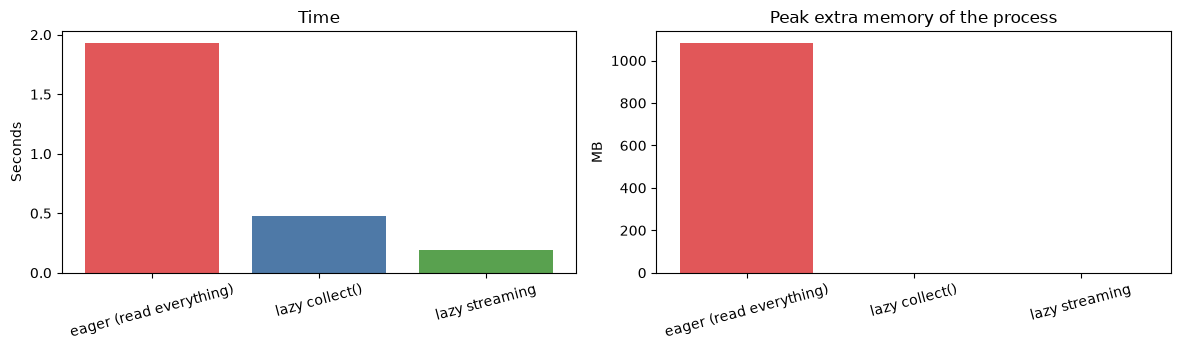

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
names = list(results)
ax1.bar(names, [results[n][0] for n in names], color=["#E15759", "#4E79A7", "#59A14F"])
ax1.set(title="Time", ylabel="Seconds")
ax2.bar(names, [results[n][1] for n in names], color=["#E15759", "#4E79A7", "#59A14F"])
ax2.set(title="Peak extra memory of the process", ylabel="MB")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

The eager version reads all 19 columns of 6 million rows into memory before filtering. The lazy versions read only the needed columns and filter while reading, so they need a fraction of the memory.

## 4. Results of the Query

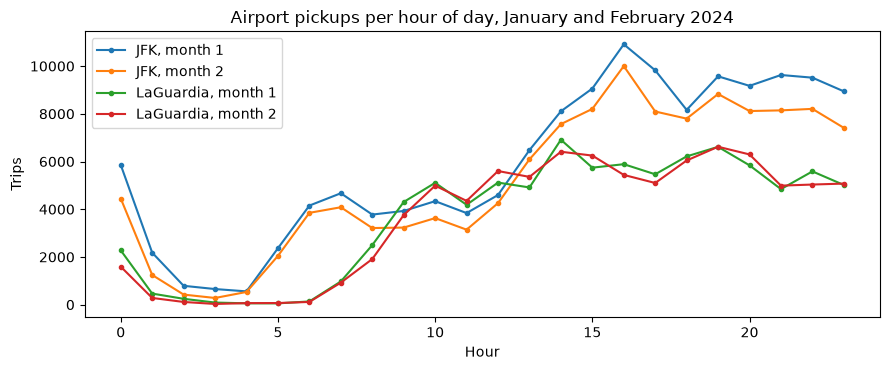

In [6]:
res = results["lazy collect()"][2].with_columns(
    airport=pl.when(pl.col("PULocationID") == 132).then(pl.lit("JFK")).otherwise(pl.lit("LaGuardia")))
fig, ax = plt.subplots(figsize=(9, 3.8))
for (airport, month), part in res.group_by("airport", "month", maintain_order=True):
    ax.plot(part["hour"], part["trips"], marker=".", label=f"{airport}, month {month}")
ax.set(title="Airport pickups per hour of day, January and February 2024", xlabel="Hour", ylabel="Trips")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Write Results without Loading: `sink_parquet`

`sink_parquet` runs a lazy query with the streaming engine and writes the result straight to a file, so neither the input nor the output must fit in memory. Typical use: a cleaning job that turns raw monthly files into a clean dataset.

In [7]:
import tempfile

out = Path(tempfile.mkdtemp()) / "clean_trips_2024q1.parquet"
duration = (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")).dt.total_seconds() / 60
clean_job = (pl.scan_parquet([JAN, FEB])
             .with_columns(duration_min=duration)
             .filter(pl.col("duration_min").is_between(1, 180), pl.col("trip_distance").is_between(0.1, 100),
                     pl.col("fare_amount").is_between(3, 500), pl.col("total_amount") > 0)
             .select("tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "duration_min",
                     "fare_amount", "tip_amount", "total_amount"))
elapsed, peak, _ = measure(lambda: clean_job.sink_parquet(out))
print(f"wrote {pl.scan_parquet(out).select(pl.len()).collect().item():,} clean rows, "
      f"{out.stat().st_size / 1e6:.0f} MB, in {elapsed:.1f} s, peak extra memory {peak:.0f} MB")

wrote 5,741,650 clean rows, 90 MB, in 1.1 s, peak extra memory 693 MB


## 6. Performance Tips

1. Start from `scan_*` instead of `read_*` whenever the data is in files.
2. Select and filter as early as possible (the optimiser helps, but clear code helps more).
3. Avoid Python functions in expressions (`map_elements`): they run row by row in Python.
4. Use `pl.Categorical` or `pl.Enum` for repeated strings.
5. Use `collect(engine="streaming")` or `sink_*` for data larger than memory.
6. Check the plan with `explain()` when a query is slower than expected.

*Insight: Write Polars pipelines lazily: `scan`, transform, then `collect` or `sink`. The optimiser reads only the columns and rows you need, and the streaming engine lets one laptop process files larger than its memory.*

## Real-World Use Case or Analogy

Lazy execution is like **ordering online instead of walking through the shop**: you submit the full list first, and the warehouse plans the shortest route, picks only what you ordered, and ships it in boxes (streaming batches) instead of bringing the whole shelf to the door.

Data teams use lazy Polars jobs to clean raw files into curated Parquet datasets on a single machine, an approach that often replaces a small Spark cluster (M13) at a fraction of the cost.